In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

In [3]:
df = pd.read_csv('titanic_toy.csv')

In [4]:
df.head()

,Age,Fare,Family,Survived
0,22.0,7.2500,1,0
1,38.0,71.2833,1,1
2,26.0,7.9250,0,1
3,35.0,53.1000,1,1
4,35.0,8.0500,0,0


In [5]:
x = df.drop(columns=['Survived'])
y = df['Survived']

In [6]:
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42)

In [14]:
x_train['Age_99'] = x_train['Age'].fillna(99)
x_train['Age_minus1'] = x_train['Age'].fillna(-1)

x_train['Fare_999'] = x_train['Fare'].fillna(999)
x_train['Fare_minus1'] = x_train['Fare'].fillna(-1)

In [18]:
x_train.sample(5)

,Age,Fare,Family,Age_99,Age_minus1,Fare_999,Fare_minus1
17,NaN,13.00,0,99.0,-1.0,13.00,13.00
83,28.0,47.10,0,28.0,28.0,47.10,47.10
351,NaN,35.00,0,99.0,-1.0,35.00,35.00
637,31.0,26.25,2,31.0,31.0,26.25,26.25
498,25.0,151.55,3,25.0,25.0,151.55,151.55


In [19]:
print('Orginal variance of the data:', x_train['Age'].var())
print('Variance of Age_99:', x_train['Age_99'].var())
print('Variance of Age_minus1:', x_train['Age_minus1'].var())

print('Orginal variance of the data:', x_train['Fare'].var())
print('Variance of Fare_999:', x_train['Fare_999'].var())
print('Variance of Fare_minus1:', x_train['Fare_minus1'].var())


Orginal variance of the data: 210.2517072477435
Variance of Age_99: 932.9665366701432
Variance of Age_minus1: 315.9955036260055
Orginal variance of the data: 2761.0314349486343
Variance of Fare_999: 47525.470595360035
Variance of Fare_minus1: 2675.2394049177024


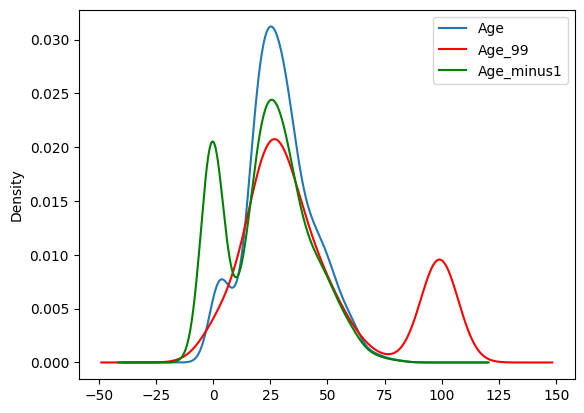

In [21]:
fig = plt.figure()
ax = fig.add_subplot(111)

# Origanal variable distribution 
x_train['Age'].plot(kind='kde', ax=ax)

# Distribution of Age_99
x_train['Age_99'].plot(kind='kde', ax=ax, color='red')

#Distribution of Age_minus1
x_train['Age_minus1'].plot(kind='kde', ax=ax, color='green')

# add legends
lines, labels = ax.get_legend_handles_labels()
ax.legend(lines, labels, loc='best')

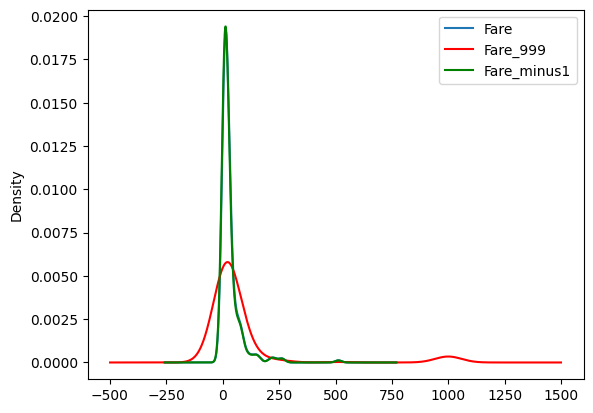

In [23]:
fig = plt.figure()
ax = fig.add_subplot(111)

# Original Distribution of Fare
x_train['Fare'].plot(kind='kde', ax=ax)

# Distribution of Fare_999
x_train['Fare_999'].plot(kind='kde', ax=ax, color='red')

# Distribution of Fare_minus1
x_train['Fare_minus1'].plot(kind='kde', ax=ax, color='green')

# add legends
lines, labels = ax.get_legend_handles_labels()
ax.legend(lines, labels, loc='best')

In [24]:
x_train.cov()

,Age,Fare,Family,Age_99,Age_minus1,Fare_999,Fare_minus1
Age,210.251707,75.481375,-6.993325,210.251707,210.251707,130.495777,69.137162
Fare,75.481375,2761.031435,18.599163,-111.965046,135.785804,2761.031435,2761.031435
Family,-6.993325,18.599163,2.830892,-6.941982,-5.034556,16.878492,17.684447
Age_99,210.251707,-111.965046,-6.941982,932.966537,-166.460682,-255.051165,-101.137070
Age_minus1,210.251707,135.785804,-5.034556,-166.460682,315.995504,262.712284,124.270305
Fare_999,130.495777,2761.031435,16.878492,-255.051165,262.712284,47525.470595,1063.944817
Fare_minus1,69.137162,2761.031435,17.684447,-101.137070,124.270305,1063.944817,2675.239405


In [25]:
x_train.corr()

,Age,Fare,Family,Age_99,Age_minus1,Fare_999,Fare_minus1
Age,1.000000,0.091482,-0.319651,1.000000,1.000000,0.039967,0.085422
Fare,0.091482,1.000000,0.207193,-0.069365,0.145071,1.000000,1.000000
Family,-0.319651,0.207193,1.000000,-0.135079,-0.168329,0.046016,0.203212
Age_99,1.000000,-0.069365,-0.135079,1.000000,-0.306576,-0.038303,-0.064017
Age_minus1,1.000000,0.145071,-0.168329,-0.306576,1.000000,0.067792,0.135159
Fare_999,0.039967,1.000000,0.046016,-0.038303,0.067792,1.000000,0.094357
Fare_minus1,0.085422,1.000000,0.203212,-0.064017,0.135159,0.094357,1.000000


## Using Sklearn


In [26]:
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42)

In [28]:
imputer1 = SimpleImputer(strategy='constant', fill_value=99)
imputer2 = SimpleImputer(strategy='constant', fill_value=99)

In [29]:
trf = ColumnTransformer([
    ('imputer1', imputer1,['Age']),
    ('imputer2', imputer2, ['Fare'])
], remainder='passthrough')

In [30]:
trf.fit(x_train)

,transformers,"[('imputer1', ...), ('imputer2', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'constant'
,fill_value,99


In [ ]:
trf.named_transformers_['imputer1'].statistics_

array([99.])

In [33]:
trf.named_transformers_['imputer2'].statistics_

array([99.])

In [31]:
x_train = trf.transform(x_train)
x_test = trf.transform(x_test)

In [34]:
x_train

array([[ 45.5   ,  28.5   ,   0.    ],
       [ 23.    ,  13.    ,   0.    ],
       [ 32.    ,   7.925 ,   0.    ],
       ...,
       [ 41.    ,  99.    ,   2.    ],
       [ 14.    , 120.    ,   3.    ],
       [ 21.    ,  77.2875,   1.    ]], shape=(712, 3))